# 5. Several Layers

> **Overview.** How does the method extend to a target network whose features are built on features?

**Setup.** The simplest generalization: each LTU has a fixed max depth, and treats everything below it (inputs and
lower LTUs) as its inputs and everything above it (higher LTUs and the outputs) as its outputs. The target network has
two hidden layers of 8 target LTUs; the learner, 16 LTUs per depth. 5 seeds; 600k steps.
- **With and without the swap.** The fixed max depth lets a depth-2 LTU that reads only inputs copy a depth-1 feature,
  stranding it where no depth-2 LTU can read it. The *swap*, a patch, moves such an LTU down to depth 1.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS, N_OUTPUTS = 1000, 10
N_DEPTHS = 2                         # hidden layers, of the target network and of the learner
TEACHER_WIDTH = 8                    # target LTUs per hidden layer
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
PER_DEPTH = 16                       # hidden LTUs per depth
N_LTUS = N_DEPTHS * PER_DEPTH
FAN_IN = 20                          # a new LTU first reads this many sources
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |outgoing weights|
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FLAT_SHARE = 0.1                     # an LTU with less than this share of its input |weights| on the layer below
                                     # acts as an LTU of that layer

# --- Experiment ---
LINEAR_STEPS = 0                     # no linear-learner phase: the LTUs are added at step 0
NUM_STEPS = 600_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps

## Target

In [3]:
def make_target(key):
    # Two hidden layers of TEACHER_WIDTH target LTUs with random +-1 weights and threshold 0, giving +-1: a depth-1
    # target LTU reads 10 random inputs, a depth-2 one 5 random inputs and 5 random depth-1 target LTUs. Each output
    # reads 2 random inputs and 2 random target LTUs of each depth, with random weights +-1/sqrt(6). Returns the target
    # LTUs' and the outputs' weights over [inputs, target LTUs].
    k = jax.random.split(key, 8)
    n = TEACHER_WIDTH
    pick = lambda key, shape, count: jnp.argsort(jnp.argsort(jax.random.uniform(key, shape))) < count  # per row
    inputs = jnp.concatenate([pick(k[0], (n, N_INPUTS), 10), pick(k[1], (n, N_INPUTS), 5)])
    hidden = jnp.zeros((2 * n, 2 * n), bool).at[n:, :n].set(pick(k[2], (n, n), 5))
    target_w = jax.random.rademacher(k[3], (2 * n, N_INPUTS + 2 * n), dtype=float) * jnp.concatenate([inputs, hidden], 1)
    reads = jnp.concatenate([pick(k[4], (N_OUTPUTS, N_INPUTS), 2), pick(k[5], (N_OUTPUTS, n), 2),
                             pick(k[6], (N_OUTPUTS, n), 2)], 1)
    return target_w, jax.random.rademacher(k[7], reads.shape, dtype=float) * reads / np.sqrt(6)


TARGET_W, TARGET_OUT = make_target(jax.random.PRNGKey(123))


def next_sample(key):
    # One sample: standard normal inputs, and the target network's outputs plus N(0, NOISE_STD^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    s = jnp.zeros(N_DEPTHS * TEACHER_WIDTH)
    for d in range(N_DEPTHS):
        rows = slice(d * TEACHER_WIDTH, (d + 1) * TEACHER_WIDTH)
        s = s.at[rows].set(jnp.where(TARGET_W[rows] @ jnp.concatenate([x, s]) > 0, 1.0, -1.0))
    return x, TARGET_OUT @ jnp.concatenate([x, s]) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

Notebook 4's learner, generalized to depth:
`redraw` draws each new LTU's parent among the units above it, `rewire` draws its first sources among those below it
by the parent's weights, `speed_up` gives it the parent's signs and the high step-size, and `swap` (under Training) is
the patch.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped like the hidden units.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


SLOT_DEPTH = jnp.arange(N_LTUS) // PER_DEPTH + 1                                   # each hidden unit's depth
DEPTHS = [slice(d * PER_DEPTH, (d + 1) * PER_DEPTH) for d in range(N_DEPTHS)]      # the hidden units of each depth
# LOWER[u, j]: whether hidden unit u may read source j of [inputs, hidden units, 1]: every input and the bias, and the
# hidden units of lower depth.
LOWER = jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(SLOT_DEPTH[None] < SLOT_DEPTH[:, None])


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, hidden units, 1 (the bias)], of which they read those in
    # `reads`; w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says
    # which of the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden unit's shadow weight on an output, and
    shadow_hidden: jax.Array    # (N_LTUS, N_LTUS) on a higher hidden unit (rows): +-1 on one output or unit, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each unit's last new connection


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0) | jnp.any(net.shadow_hidden != 0, 0)


def parent_weights(net):
    # Shaped like w['hidden']: each hidden unit's shadow weight times its parent's weights on the sources it may
    # read (an output's weight on an input is the linear learner's), 0 elsewhere and on the bias.
    targets = net.shadow.T @ net.w['output'] + net.shadow_hidden.T @ (net.w['hidden'] * net.reads)
    return targets.at[:, -1].set(0.0) * LOWER


def usefulness(net):
    # Each hidden unit's sum of |outgoing weights|, to the outputs and to higher hidden units.
    return (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
            + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))


def init_net(key, units, sampled):
    # `units` hidden units (the rest of the N_LTUS slots left empty), each pair of a depth wired like one target LTU of
    # that depth in turn, reading its inputs, the units of lower depths wired like the target LTUs it reads, and the
    # bias, with LeCun uniform weights over their fan-in; their shadow weights +1 and -1 alternately, each on an output
    # drawn at random among those that read its target LTU (among all outputs if sampled, or if none does); every other
    # weight at 0.
    w_key, out_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    assigned = (SLOT_DEPTH - 1) * TEACHER_WIDTH + slot % PER_DEPTH // 2 % TEACHER_WIDTH  # the target LTU each is wired like
    target_reads = TARGET_W[assigned] != 0
    wired = jnp.concatenate([target_reads[:, :N_INPUTS], target_reads[:, N_INPUTS:][:, assigned],
                             jnp.ones((N_LTUS, 1), bool)], 1)
    reads = wired & LOWER
    fan_in = reads[:, :-1].sum(1, keepdims=True)
    readers = (TARGET_OUT[:, N_INPUTS + assigned] != 0) | sampled
    readers = readers | ~readers.any(0)
    shadow_out = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == shadow_out) * sign
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_LTUS)),
               jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)))


def redraw(net, key, replaced):
    # The `replaced` hidden units' new shadow weights, +1 or -1 by slot, each on a unit of a higher layer, their parent:
    # a layer drawn uniformly among those above the unit's depth, the outputs (layer N_DEPTHS + 1) included, then a
    # unit of it at random.
    layer_key, unit_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    layer = jax.random.randint(layer_key, (N_LTUS,), SLOT_DEPTH + 1, N_DEPTHS + 2)
    on_output = layer > N_DEPTHS
    index = jax.random.randint(unit_key, (N_LTUS,), 0, jnp.where(on_output, N_OUTPUTS, PER_DEPTH))
    sign = jnp.where(slot % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == index) * jnp.where(on_output, sign, 0.0)
    shadow_hidden = (slot[:, None] == (layer - 1) * PER_DEPTH + index) * jnp.where(on_output, 0.0, sign)
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow),
                        shadow_hidden=jnp.where(replaced, shadow_hidden, net.shadow_hidden))


def rewire(net, key, replaced, rows, random):
    # The `rows` hidden units (a mask over slots, among the `replaced` units) each read FAN_IN sources (no more than
    # their parent has nonzero weights on) and the bias, the sources, inputs and lower-depth units alike, drawn without
    # replacement with probability proportional to the square of their parent's weight on them (uniformly among the
    # sources they may read, if random) (Gumbel top-k), with fresh LeCun uniform weights over their fan-in, output
    # weights at 0, and fresh statistics, Autostep state and gradient sums; the other units' connections from the
    # replaced units are cut. Then every unit reads the units with shadow weights on it, connections it lacks starting
    # at weight 0 with step-size FAST_STEP_SIZE.
    draw_key, w_key = jax.random.split(key)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced units
    weights = jnp.where(cut, 0.0, jnp.where(random, LOWER, parent_weights(net)))[:, :-1]
    fan_in = jnp.minimum(FAN_IN, (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    changed = rows[:, None] | cut
    reads = jnp.where(changed, reads, net.reads)
    served = jnp.zeros_like(reads).at[:, N_INPUTS:-1].set(net.shadow_hidden != 0) & ~reads
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    beta = {**beta, 'hidden': jnp.where(served, jnp.log(FAST_STEP_SIZE), beta['hidden'])}
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=reads | served, opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' weights keep their magnitudes but take the signs of their shadow weight times their
    # parent's weights on those sources (keeping theirs where that weight is 0), and the step-sizes of all their
    # weights but the bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & replaced[:, None]
    parent = parent_weights(net)
    hidden = jnp.where(sources & (parent != 0), jnp.abs(net.w['hidden']) * jnp.sign(parent), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times
    # their root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the hidden units computed
    # depth by depth, each shadow weight standing in for its hidden unit's weight to that output or higher unit in the
    # backward pass while the real one is smaller in magnitude, the other weights used as they are. Returns the new
    # network and the squared error on this sample averaged over the outputs, before learning from it, and adds
    # dL/dz * source to each hidden unit's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # hidden unit and dL/dz.

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}

        def back(shadow, real):
            # The weights used in the backward pass: each shadow weight while the real one is smaller in magnitude.
            return jax.lax.stop_gradient(jnp.where((shadow != 0) & (jnp.abs(real) < 1.0), shadow, real))

        hidden_back = back(net.shadow_hidden, w['hidden'][:, N_INPUTS:-1])
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            through_back = hidden_back[rows] @ a
            z = (w['hidden'][rows] @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through_back
                 - jax.lax.stop_gradient(through_back))
            b = ltu(z + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        through_back = (back(net.shadow, w['output'][:, N_INPUTS:-1]) * net.mask[:, N_INPUTS:-1]) @ a
        prediction = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (source, jnp.concatenate(hs), jnp.concatenate(means))

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1]), 2 * loss / N_OUTPUTS

## Training

In [5]:
def swap(net, i, j):
    # Slots i and j exchange their units, but the shadow weights on each slot stay on it; the unit arriving at slot i,
    # of the lower depth, loses its connections from units no longer below it.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols], mask=net.mask[:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       shadow_hidden=net.shadow_hidden[:, perm],
                       candidates=net.candidates[perm][:, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i].set(~LOWER[i])
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def train(net, key, sampled, period, fast, grows, random, swaps, add_step, num_steps):
    # num_steps online network-Autostep steps, the hidden units added at add_step (first given new shadow weights and
    # rewired, if sampled), and every `period` steps after that (never if period is 0) the REPLACED of them with the
    # smallest sum of |outgoing weights| given new shadow weights and rewired, after, from the top, the strongest unit of
    # each depth acting as a unit of the depth below (if any) swaps slots with the weakest unit of that depth, if weaker;
    # every unit added or rewired sped up if fast, and every WINDOW steps after the units are added, each grows if grows
    # (before any rewiring); new units wired at random if random, and swaps only if swaps. Returns each window's
    # mean squared error.
    wire_key, key = jax.random.split(key)

    def one_step(net, inputs):
        step, key = inputs
        x, y = next_sample(key)
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired, at_random):
        # The replaced units given new shadow weights and rewired (if rewired; their sources drawn uniformly if
        # at_random), and sped up (if fast), from the top depth down, so that units with shadow weights on higher units
        # draw on their new weights.
        keys = jax.random.split(key, N_DEPTHS + 1)
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), redraw(net, keys[0], replaced), net)
        for depth, depth_key in zip(DEPTHS[::-1], keys[1:]):
            rows = replaced & jnp.zeros(N_LTUS, bool).at[depth].set(True)
            rewired_net = rewire(net, depth_key, replaced, rows, at_random)
            net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewired_net, net)
            net = jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, rows), net)
        return net

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        outgoing = usefulness(net)
        for depth in range(N_DEPTHS, 1, -1):     # moves from depth to depth - 1, from the top
            links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
            below = jnp.sum(jnp.where(SLOT_DEPTH == depth - 1, links[:, N_INPUTS:], 0.0), 1)
            flat = (SLOT_DEPTH == depth) & active(net) & (below < FLAT_SHARE * links.sum(1))
            mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
            weak = jnp.argmin(jnp.where(active(net) & (SLOT_DEPTH == depth - 1), outgoing, jnp.inf))
            moved = due & swaps & flat.any() & (outgoing[mover] > outgoing[weak])
            net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
            outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
        weakest = jnp.argsort(jnp.where(active(net), outgoing, jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(N_LTUS, bool).at[weakest].set(True), True,
                         random)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, active(net), sampled, True)    # the first LTUs: their parents have no weights yet
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs):
    # Each (units, sampled, period, fast, grows, random, swaps) of configs: `units` hidden LTUs reading sampled inputs
    # if sampled, searched every `period` steps (0: never), and wired like the target network otherwise (no LTUs: the
    # linear learner alone), learning fast if fast and growing if grows, each on N_SEEDS seeds, vmapped together. Seed s
    # gives every run the same samples. Returns {config: the RMSE of each window from step 1, shaped (seed, window)}.
    units, sampled, period, fast, grows, random, swaps, seed = (
        jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(init_net)(keys(0), units, sampled)
    train_all = jax.jit(jax.vmap(lambda n, k, s, p, f, g, r, w: train(n, k, s, p, f, g, r, w, LINEAR_STEPS,
                                                                      LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), sampled, period, fast, grows, random, swaps)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
LINEAR = (0, False, 0, False, False, False, False)
REFERENCE = (N_LTUS, False, 0, True, False, False, False)
SEARCH = (N_LTUS, True, PERIOD, True, True, False, True)
NO_SWAP = (N_LTUS, True, PERIOD, True, True, False, False)
started = perf_counter()
rmse = run([SEARCH, NO_SWAP, REFERENCE, LINEAR])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

2026-11-05 12:27:28.479996: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-05 12:27:28.480049: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


20 runs in 62s


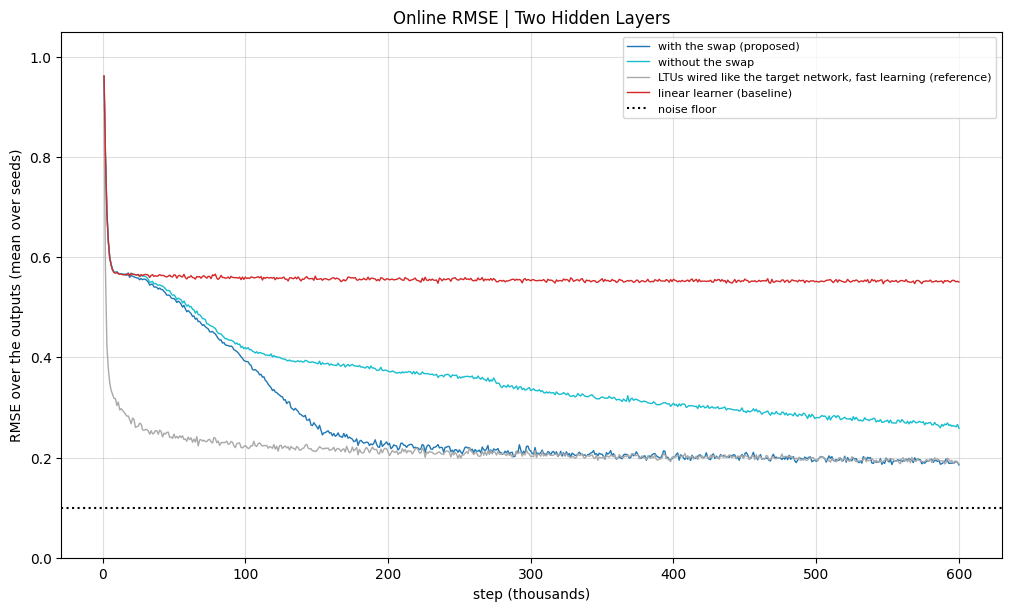

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {'with the swap (proposed)': (SEARCH, 'tab:blue'),
           'without the swap': (NO_SWAP, 'tab:cyan'),
           'LTUs wired like the target network, fast learning (reference)': (REFERENCE, 'darkgray'),
           'linear learner (baseline)': (LINEAR, 'tab:red')}

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for label, (config, color) in METHODS.items():
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands)', ylabel='RMSE over the outputs (mean over seeds)',
       ylim=(0, 1.05), title='Online RMSE | Two Hidden Layers')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

With the swap, the simplest generalization finds the two-layer target network; without it, learning is much slower.

## Details

**Target.** $N = 1000$ standard normal inputs. Target LTUs have random $\pm 1$ weights and threshold 0. A depth-1
target LTU reads 10 random inputs; a depth-2 one reads 5 random inputs and 5 random depth-1 target LTUs. 10 outputs,
each reading 2 random inputs and 2 random target LTUs of each depth with weights $\pm 1/\sqrt{6}$, plus
$N(0, 0.1^2)$ noise (dotted line). One target network for every seed.

**Learner.** As in notebook 4. A new LTU's parent is drawn among the units above it: a higher layer uniformly, then a
unit of that layer. A parent that is an LTU reads it. The new LTU draws its 20 first sources among the units below it
by the parent's weights, and grows over them. The LTUs are added at step 0, the first reading random sources with random signs, as in notebook 4.
Every 10k steps, the swap runs, then search replaces the 4 LTUs with the smallest sum of |outgoing weights|. Replaced
LTUs are rewired from the top depth down, so that new depth-1 LTUs draw on their new parents' weights.

**Why copies strand features.** A depth-2 LTU that reads only inputs is a depth-1 LTU in a depth-2 slot. Once it
copies a depth-1 feature, the outputs switch to the copy, and the depth-1 LTU with the original is replaced. The
feature is left where no depth-2 LTU can read it.

**The swap.** At each search step, consider the depth-2 LTUs with less than 10% of their input |weights| on depth 1.
The one with the largest sum of |outgoing weights| swaps slots with the weakest depth-1 LTU, if that one is weaker,
and loses its connections from depth 1. It is a patch: a better solution would not fix each LTU's max depth.